First five rows:
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
mem

c:\Users\varun\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\varun\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\varun\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\varun\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\varun\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

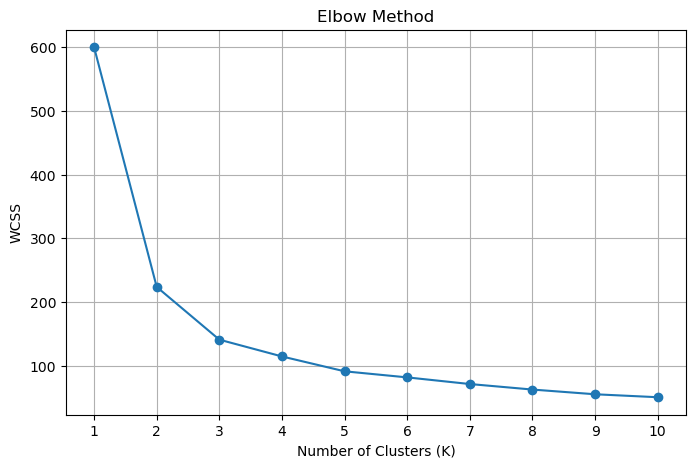

c:\Users\varun\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(



Cluster Assignments:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 0 0 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 2 0 0 0
 0 2 2 2 0 0 0 0 0 0 0 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 2 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]

Cluster Counts:
0    53
1    50
2    47
Name: count, dtype: int64


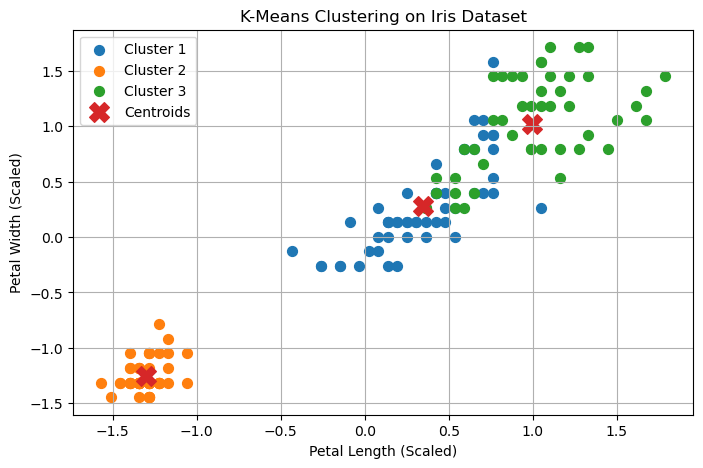

In [1]:
# Step 1: Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Step 2: Load the Iris dataset
data = pd.read_csv('iris.csv')

# Step 3: Explore the dataset
print("First five rows:")
print(data.head())

print("\nDataset Information:")
data.info()

print("\nStatistical Description:")
print(data.describe(include='all'))

print("\nMissing Values:")
print(data.isnull().sum())

# Step 4: Remove unnecessary columns and separate features
# Id is not a flower measurement; Species is the actual label.
# We do not use Species because K-Means is unsupervised.
X = data.drop(columns=['Id', 'Species'], errors='ignore')

# Handle missing numerical values, if any
X = X.fillna(X.median(numeric_only=True))

print("\nFeatures used for clustering:")
print(X.head())

# Step 5: Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 6: Determine optimal K using the Elbow Method
wcss = []

for i in range(1, 11):
    kmeans = KMeans(
        n_clusters=i,
        init='k-means++',
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plot the Elbow graph
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

# Step 7: Apply K-Means with K = 3
kmeans = KMeans(
    n_clusters=3,
    init='k-means++',
    random_state=42,
    n_init=10
)

y_kmeans = kmeans.fit_predict(X_scaled)

# Step 8: Display cluster assignments
print("\nCluster Assignments:")
print(y_kmeans)

print("\nCluster Counts:")
print(pd.Series(y_kmeans).value_counts().sort_index())

# Step 9: Visualize the clusters using petal length and width
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[y_kmeans == 0, 2],
    X_scaled[y_kmeans == 0, 3],
    s=50,
    label='Cluster 1'
)

plt.scatter(
    X_scaled[y_kmeans == 1, 2],
    X_scaled[y_kmeans == 1, 3],
    s=50,
    label='Cluster 2'
)

plt.scatter(
    X_scaled[y_kmeans == 2, 2],
    X_scaled[y_kmeans == 2, 3],
    s=50,
    label='Cluster 3'
)

# Plot the cluster centroids
plt.scatter(
    kmeans.cluster_centers_[:, 2],
    kmeans.cluster_centers_[:, 3],
    s=200,
    marker='X',
    label='Centroids'
)

plt.title('K-Means Clustering on Iris Dataset')
plt.xlabel('Petal Length (Scaled)')
plt.ylabel('Petal Width (Scaled)')
plt.legend()
plt.grid(True)
plt.show()